# Objectives for PCA
#### PCA analysis of ODE simulations: Take simulation outputs and perform PCA.
#### Comparison of PCA distance and intermitotic time: Calculate complete distance for a cell cycle and compare to the times.
#### Vector analysis of stochastic output

In [1]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import numpy as np
import os
import glob
from scipy.signal import savgol_filter
from scipy.signal import find_peaks
import pandas as pd
from pathlib import Path
import re
import sys
from sklearn.decomposition import PCA

### Files are loaded from the abbreviated ODE stiffness sweep (changing AKT and FAK input) into a dataframe

In [89]:
filenames_ODE = sorted(glob.glob("C:/Users/olesk/ECM_mod_output/lyap_odes/*range*.csv"))
filenames_ODE[1999]

'C:/Users/olesk/ECM_mod_output/lyap_odes\\erl_range_9-23_1000.csv'

In [90]:
prot_tmp_ODE = pd.read_csv(filenames_ODE[1999], sep=",", header=None)
prot_tmp_ODE.columns = ["skp2", "p21", "pp21", "cdh1a", "myc", "cycD", "cycD-p21", 
    "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
    "cycB", "cycB-p21", "cdc20"]
#prot_tmp_ODE = pd.read_csv(filenames_ODE[0], sep=",").drop(columns='Unnamed: 0')
prot_tmp_ODE_short = prot_tmp_ODE.iloc[19:round(len(prot_tmp_ODE)/2),:]
prot_tmp_ODE_short

,skp2,p21,pp21,cdh1a,myc,cycD,cycD-p21,Rb,pRb,E2F,E2F-Rb,cycE,cycE-p21,cycA,cycA-p21,cycB,cycB-p21,cdc20
19,17.369,7.1087,0.27950,4.3601,103.54,34.122,2.0491,138.78,28.016,2.5676,110.13,1.03930,0.092823,16.325,4.6702,140.07,0.71424,184.74
20,17.458,7.2280,0.29670,4.4768,103.54,34.108,2.1126,138.92,27.878,2.5679,110.16,1.08750,0.097412,14.521,4.5953,138.46,0.73241,184.74
21,17.544,7.3371,0.31472,4.5972,103.54,34.096,2.1758,139.01,27.782,2.5694,110.19,1.13840,0.102390,12.855,4.5127,136.77,0.75054,184.70
22,17.628,7.4349,0.33350,4.7215,103.54,34.085,2.2387,139.06,27.727,2.5719,110.22,1.19190,0.107760,11.326,4.4232,135.03,0.76856,184.62
23,17.710,7.5202,0.35295,4.8493,103.54,34.075,2.3008,139.07,27.712,2.5753,110.25,1.24810,0.113500,9.937,4.3276,133.23,0.78641,184.50
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
287,17.061,6.6524,0.22842,4.0001,103.54,34.173,1.8374,138.00,28.829,2.5743,110.03,0.89821,0.080267,23.289,4.8553,144.95,0.65381,184.27
288,17.156,6.7969,0.24267,4.1031,103.54,34.157,1.9005,138.30,28.532,2.5708,110.06,0.93735,0.083589,21.058,4.8110,143.58,0.67179,184.49
289,17.248,6.9352,0.25782,4.2103,103.54,34.141,1.9640,138.54,28.286,2.5686,110.09,0.97915,0.087283,18.948,4.7569,142.13,0.68989,184.64
290,17.339,7.0662,0.27386,4.3216,103.54,34.127,2.0275,138.74,28.087,2.5675,110.12,1.02360,0.091356,16.966,4.6935,140.60,0.70805,184.72


In [91]:
upper_range = round(len(prot_tmp_ODE_short)*0.1,2)
time = np.linspace(0,upper_range-0.1,len(prot_tmp_ODE_short))
#time = np.arange(0,upper_range,0.01).tolist()
prot_tmp_ODE_short.insert(0,'Time',time)
prot_tmp_ODE_short.insert(0,'Ind',[0]*len(prot_tmp_ODE_short))
prot_tmp_ODE_short


,Ind,Time,skp2,p21,pp21,cdh1a,myc,cycD,cycD-p21,Rb,pRb,E2F,E2F-Rb,cycE,cycE-p21,cycA,cycA-p21,cycB,cycB-p21,cdc20
19,0,0.0,17.369,7.1087,0.27950,4.3601,103.54,34.122,2.0491,138.78,28.016,2.5676,110.13,1.03930,0.092823,16.325,4.6702,140.07,0.71424,184.74
20,0,0.1,17.458,7.2280,0.29670,4.4768,103.54,34.108,2.1126,138.92,27.878,2.5679,110.16,1.08750,0.097412,14.521,4.5953,138.46,0.73241,184.74
21,0,0.2,17.544,7.3371,0.31472,4.5972,103.54,34.096,2.1758,139.01,27.782,2.5694,110.19,1.13840,0.102390,12.855,4.5127,136.77,0.75054,184.70
22,0,0.3,17.628,7.4349,0.33350,4.7215,103.54,34.085,2.2387,139.06,27.727,2.5719,110.22,1.19190,0.107760,11.326,4.4232,135.03,0.76856,184.62
23,0,0.4,17.710,7.5202,0.35295,4.8493,103.54,34.075,2.3008,139.07,27.712,2.5753,110.25,1.24810,0.113500,9.937,4.3276,133.23,0.78641,184.50
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
287,0,26.8,17.061,6.6524,0.22842,4.0001,103.54,34.173,1.8374,138.00,28.829,2.5743,110.03,0.89821,0.080267,23.289,4.8553,144.95,0.65381,184.27
288,0,26.9,17.156,6.7969,0.24267,4.1031,103.54,34.157,1.9005,138.30,28.532,2.5708,110.06,0.93735,0.083589,21.058,4.8110,143.58,0.67179,184.49
289,0,27.0,17.248,6.9352,0.25782,4.2103,103.54,34.141,1.9640,138.54,28.286,2.5686,110.09,0.97915,0.087283,18.948,4.7569,142.13,0.68989,184.64
290,0,27.1,17.339,7.0662,0.27386,4.3216,103.54,34.127,2.0275,138.74,28.087,2.5675,110.12,1.02360,0.091356,16.966,4.6935,140.60,0.70805,184.72


### Example plot: Cdc20 Dynamics

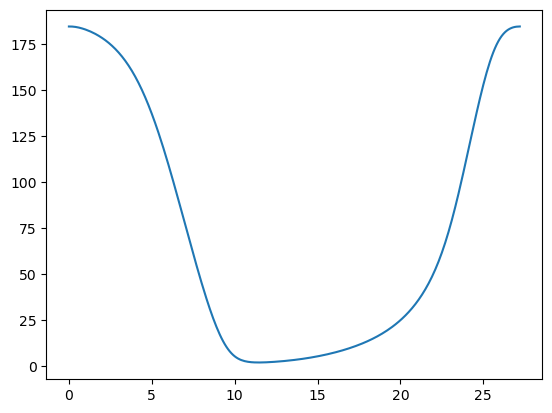

In [92]:
plt.plot(prot_tmp_ODE_short.Time, prot_tmp_ODE_short.cdc20)

In [6]:
# What indices represent a full period?
period_ind = prot_tmp_ODE[prot_tmp_ODE['cdc20']==prot_tmp_ODE['cdc20'].iloc[0]].index.values
# The time between the first data point and half the total time is a period:
period_ind

array([0], dtype=int64)

### Files are loaded from stochastic simulation outputs

In [139]:
filenames = sorted(glob.glob("C://Users//olesk//ECM_mod_output//stoch*orig.csv"))
filenames_sp = [filenames[2], filenames[3], filenames[0], filenames[1], filenames[4], filenames[5]]
filenames_sp

['C://Users//olesk//ECM_mod_output\\stoch_sim_soft_DMSO_param_orig.csv',
 'C://Users//olesk//ECM_mod_output\\stoch_sim_soft_erl_param_orig.csv',
 'C://Users//olesk//ECM_mod_output\\stoch_sim_int_DMSO_param_orig.csv',
 'C://Users//olesk//ECM_mod_output\\stoch_sim_int_erl_param_orig.csv',
 'C://Users//olesk//ECM_mod_output\\stoch_sim_stiff_DMSO_param_orig.csv',
 'C://Users//olesk//ECM_mod_output\\stoch_sim_stiff_erl_param_orig.csv']

In [147]:
prot_tmp_stoch = pd.read_csv(filenames_stoch[0], sep=",", header=None, usecols = range(0,19))
prot_tmp_stoch.columns = ["skp2", "p21", "pp21", "cdh1a", "cdh1i", "myc", "cycD", "cycD-p21", 
    "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
    "cycB", "cycB-p21", "cdc20"]
prot_tmp_stoch = prot_tmp_stoch.drop(columns=['cdh1i'])

upper_range = round(len(prot_tmp_stoch)*0.1,2)
time = np.linspace(0,upper_range-0.1,len(prot_tmp_stoch))
prot_tmp_stoch.insert(0,'Time',time)

prot_tmp_stoch

,Time,skp2,p21,pp21,cdh1a,myc,cycD,cycD-p21,Rb,pRb,E2F,E2F-Rb,cycE,cycE-p21,cycA,cycA-p21,cycB,cycB-p21,cdc20
0,0.0,12.0,1.0,16.0,6.0,139.0,47.0,1.0,5.0,242.0,124.0,19.0,163.0,3.0,102.0,2.0,17.0,2.0,6.0
1,0.1,12.0,1.0,15.0,8.0,138.0,52.0,1.0,4.0,243.0,123.0,18.0,158.0,3.0,105.0,2.0,17.0,2.0,6.0
2,0.2,12.0,0.0,17.0,6.0,140.0,50.0,1.0,5.0,251.0,132.0,9.0,164.0,3.0,105.0,2.0,18.0,2.0,6.0
3,0.3,13.0,0.0,14.0,7.0,144.0,48.0,1.0,6.0,230.0,108.0,31.0,162.0,3.0,105.0,2.0,19.0,2.0,6.0
4,0.4,13.0,1.0,12.0,13.0,148.0,46.0,1.0,4.0,231.0,105.0,32.0,158.0,3.0,108.0,2.0,19.0,2.0,7.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
199996,19999.6,17.0,0.0,11.0,5.0,143.0,57.0,1.0,10.0,212.0,70.0,36.0,64.0,3.0,143.0,7.0,66.0,2.0,31.0
199997,19999.7,19.0,4.0,7.0,6.0,141.0,59.0,1.0,9.0,219.0,79.0,30.0,62.0,2.0,144.0,6.0,66.0,2.0,37.0
199998,19999.8,19.0,0.0,10.0,5.0,141.0,55.0,1.0,6.0,223.0,80.0,29.0,62.0,2.0,142.0,8.0,68.0,2.0,40.0
199999,19999.9,19.0,5.0,9.0,6.0,139.0,54.0,1.0,10.0,213.0,73.0,35.0,55.0,2.0,142.0,7.0,70.0,2.0,40.0


# PCA Analysis on one ODE Dataset

In [93]:
# choose number of components and define pca
pca = PCA(n_components = 2)

# use the pca on the data (without the time column)
principalComponents = pca.fit_transform(prot_tmp_ODE_short.iloc[:,2:])

# add results to a dataframe
principal = pd.DataFrame(data = principalComponents, columns = ['principal component 1', 'principal component 2'])
principal

,principal component 1,principal component 2
0,197.673592,-41.579347
1,197.666956,-40.199905
2,197.551784,-38.848696
3,197.340466,-37.534891
4,197.030514,-36.256489
...,...,...
268,196.842496,-46.367780
269,197.236989,-44.911888
270,197.501763,-43.473252
271,197.645603,-42.053966


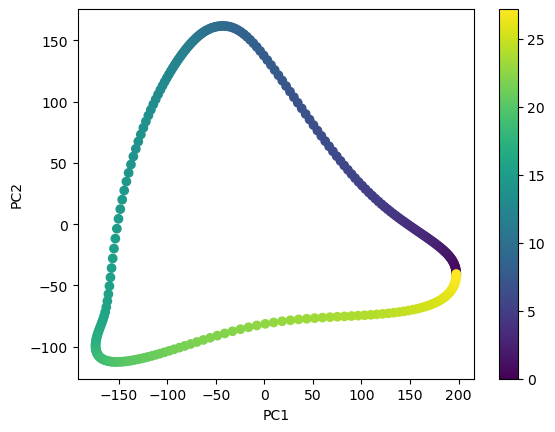

In [94]:
# Scatterplot of the PCA results, color corresponds to time

# Only one period of time is shown
period = round(len(principal))

fig = plt.scatter(principal.iloc[0:period, 0], principal.iloc[0:period, 1], c=prot_tmp_ODE_short['Time'].iloc[0:period])
plt.colorbar(fig)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()

# PCA on all Data

## ODE Data

In [47]:
# Put all DMSO and ERL data in separate dataframes

data_DMSO = pd.DataFrame()
data_ERL = pd.DataFrame()
IMT_DMSO = []
IMT_ERL = []

n=0
n1=0

for i in range(0,len(filenames_ODE)):
    if "dmso" in filenames_ODE[i]:
        prot_tmp_ODE = pd.read_csv(filenames_ODE[i], sep=",", header=None)
        prot_tmp_ODE.columns = ["skp2", "p21", "pp21", "cdh1a", "myc", "cycD", "cycD-p21", 
            "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
            "cycB", "cycB-p21", "cdc20"]
        prot_tmp_ODE_short = prot_tmp_ODE.iloc[19:round(len(prot_tmp_ODE)/2),:]
        prot_tmp_ODE_short.reset_index()
        
        upper_range = round(len(prot_tmp_ODE_short)*0.1,2)
        time = np.linspace(0,upper_range-0.1,len(prot_tmp_ODE_short))
        IMT = time[-1]
        IMT_DMSO.append(IMT)
        
        prot_tmp_ODE_short.insert(0,'IMT',[IMT]*len(prot_tmp_ODE_short))
        prot_tmp_ODE_short.insert(0,'Time',time)
        prot_tmp_ODE_short.insert(0,'Ind',[n]*len(prot_tmp_ODE_short))
    
        if data_DMSO.empty:
            data_DMSO = prot_tmp_ODE_short
        else:
            data_DMSO = pd.concat([data_DMSO, prot_tmp_ODE_short], axis=0, ignore_index=True)
            
        n+=1
        
    else:
        prot_tmp_ODE = pd.read_csv(filenames_ODE[i], sep=",", header=None)
        prot_tmp_ODE.columns = ["skp2", "p21", "pp21", "cdh1a", "myc", "cycD", "cycD-p21", 
            "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
            "cycB", "cycB-p21", "cdc20"]
        prot_tmp_ODE_short = prot_tmp_ODE.iloc[19:round(len(prot_tmp_ODE)/2),:]
        prot_tmp_ODE_short.reset_index()
        
        upper_range = round(len(prot_tmp_ODE_short)*0.1,2)
        time = np.linspace(0,upper_range-0.1,len(prot_tmp_ODE_short))
        IMT = time[-1]
        IMT_ERL.append(IMT)
        
        prot_tmp_ODE_short.insert(0,'IMT',[IMT]*len(prot_tmp_ODE_short))
        prot_tmp_ODE_short.insert(0,'Time',time)
        prot_tmp_ODE_short.insert(0,'Ind',[n1]*len(prot_tmp_ODE_short))
        
    
        if data_ERL.empty:
            data_ERL = prot_tmp_ODE_short
        else:
            data_ERL = pd.concat([data_ERL, prot_tmp_ODE_short], axis=0, ignore_index=True)
            
        n1+=1

In [117]:
# All data together
data_ODE = pd.concat([data_DMSO, data_ERL], axis=0, ignore_index=True)
len(data_DMSO)

231759

In [111]:
# use the pca on all the data (without the time column)
principalComponents = pca.fit_transform(data_ODE.iloc[:,3:])

# add results to a dataframe
principal = pd.DataFrame(data = principalComponents, columns = ['principal component 1', 'principal component 2'])
len(principal)

595151

In [108]:
# use the pca on all the data (without the time column)
principalComponents_ERL = pca.fit_transform(data_ERL.iloc[:,3:])

# add results to a dataframe
principal_ERL = pd.DataFrame(data = principalComponents_ERL, columns = ['principal component 1', 'principal component 2'])
len(principal_ERL)

363392

In [54]:
norm = plt.Normalize(20, 75)
cm = plt.cm.viridis
sm = plt.cm.ScalarMappable(cmap=cm, norm=norm)

### Scatter plot of all ODE data

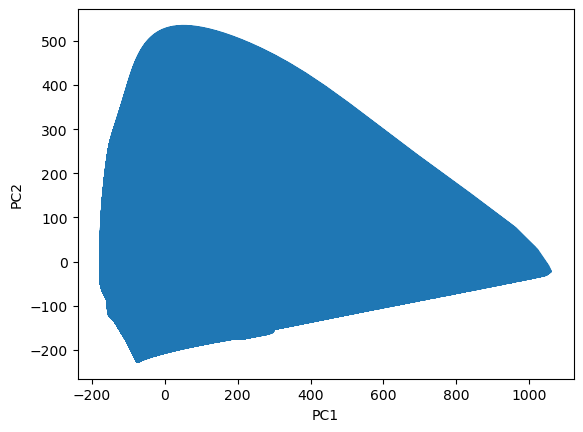

In [45]:
# Scatterplot of all PCA results, color corresponds to time

#fig = plt.scatter(principal.iloc[:, 0], principal.iloc[:, 1], c=data_ODE['Time'])
fig = plt.plot(principal.iloc[::10, 0], principal.iloc[::10, 1], )
#plt.colorbar(fig)
plt.xlabel('PC1')
plt.ylabel('PC2')
#plt.savefig('PCA_fig.png')
plt.show()

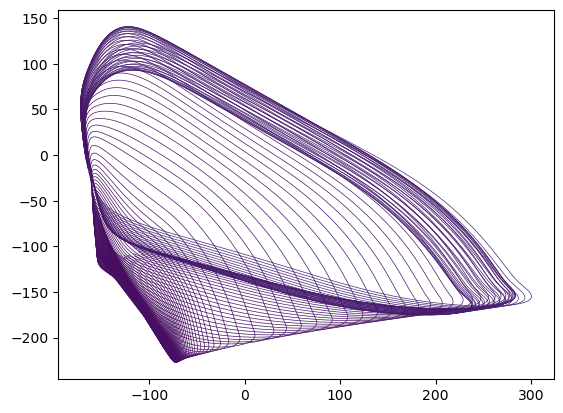

In [116]:
ii=0
fig = plt.figure()
for n in range(0,1000,10):
    tmp_ind = data_DMSO.index[data_DMSO['Ind'] == n].tolist()
    plt.plot(principal.iloc[tmp_ind, 0], principal.iloc[tmp_ind, 1], color = cm(norm(IMT_DMSO[n])), lw=0.5)
    

In [123]:
erl_ind = data_ERL[data_ERL['Ind'] == 1].index.to_list()

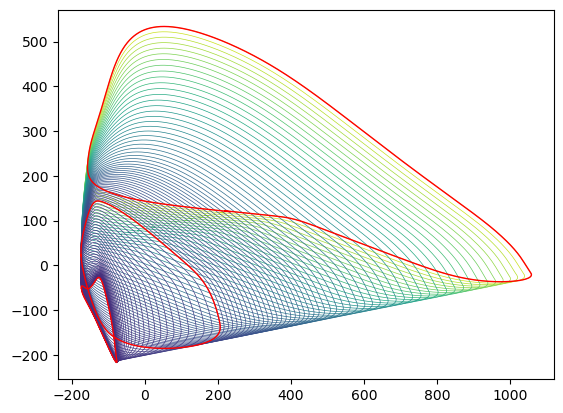

In [133]:
ii=0
fig = plt.figure()
for n in range(0,1000,10):
    erl_ind = data_ERL[data_ERL['Ind'] == n].index.to_list()
    tmp_ind = [ind + len(data_DMSO) for ind in erl_ind]
    plt.plot(principal.iloc[tmp_ind, 0], principal.iloc[tmp_ind, 1], color = cm(norm(IMT_ERL[n])), lw=0.5)
    
erl_ind = data_ERL[data_ERL['Ind'] == 0].index.to_list()
tmp_ind = [ind + len(data_DMSO) for ind in erl_ind]
plt.plot(principal.iloc[tmp_ind, 0], principal.iloc[tmp_ind, 1], color = 'red', lw=1)

erl_ind = data_ERL[data_ERL['Ind'] == 499].index.to_list()
tmp_ind = [ind + len(data_DMSO) for ind in erl_ind]
plt.plot(principal.iloc[tmp_ind, 0], principal.iloc[tmp_ind, 1], color = 'red', lw=1)

erl_ind = data_ERL[data_ERL['Ind'] == 999].index.to_list()
tmp_ind = [ind + len(data_DMSO) for ind in erl_ind]
plt.plot(principal.iloc[tmp_ind, 0], principal.iloc[tmp_ind, 1], color = 'red', lw=1)

### Scatter plot of all DMSO data

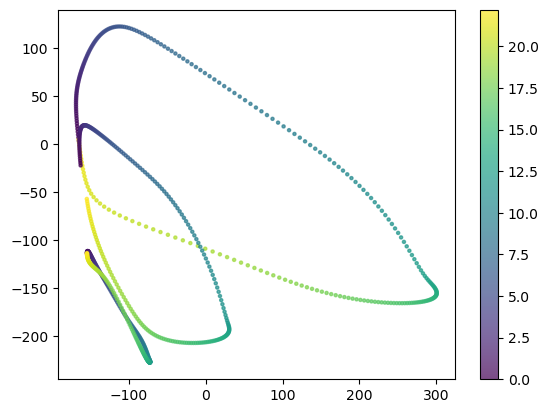

In [46]:
dmso_lo = data_DMSO.index[data_DMSO['Ind'] == 0].tolist()
dmso_int = data_DMSO.index[data_DMSO['Ind'] == 499].tolist()
dmso_hi = data_DMSO.index[data_DMSO['Ind'] == 999].tolist()

fig = plt.figure()
plt.scatter(principal.iloc[dmso_lo, 0], principal.iloc[dmso_lo, 1], 
                  c=data_ODE['Time'][dmso_lo], s=5, alpha=0.7)
plt.scatter(principal.iloc[dmso_int, 0], principal.iloc[dmso_int, 1], 
                  c=data_ODE['Time'][dmso_int], s=5, alpha=0.7)
plt.scatter(principal.iloc[dmso_hi, 0], principal.iloc[dmso_hi, 1], 
                  c=data_ODE['Time'][dmso_hi], s=5, alpha=0.7)
plt.colorbar()


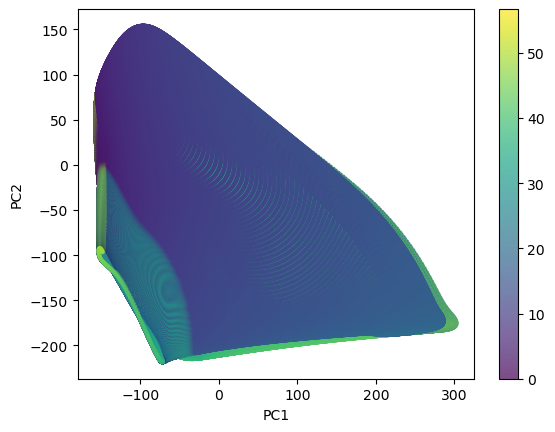

In [63]:
# Color corresponds to time

DMSO_upper_ODE = int(len(data_DMSO) - 1)

fig = plt.scatter(principal.iloc[0:DMSO_upper_ODE, 0], principal.iloc[0:DMSO_upper_ODE, 1], 
                  c=data_ODE['Time'][0:DMSO_upper_ODE], s=5, alpha=0.7)
plt.colorbar(fig)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.savefig('PCA_DMSOfig.png')
plt.show()

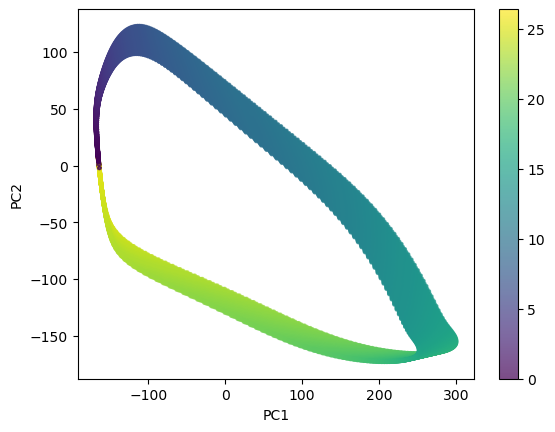

In [17]:
# Color corresponds to time
n = 20000
DMSO_upper_ODE = int(len(data_DMSO) - 1)

fig = plt.scatter(principal.iloc[0:n, 0], principal.iloc[0:n, 1], 
                  c=data_ODE['Time'][0:n], s=5, alpha=0.7)
plt.colorbar(fig)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.savefig('PCA_DMSOfig.png')
plt.show()

### Scatter plot of all ERL data

453279     0.0
453280     0.1
453281     0.2
453282     0.3
453283     0.4
          ... 
453586    30.7
453587    30.8
453588    30.9
453589    31.0
453590    31.1
Name: Time, Length: 312, dtype: float64

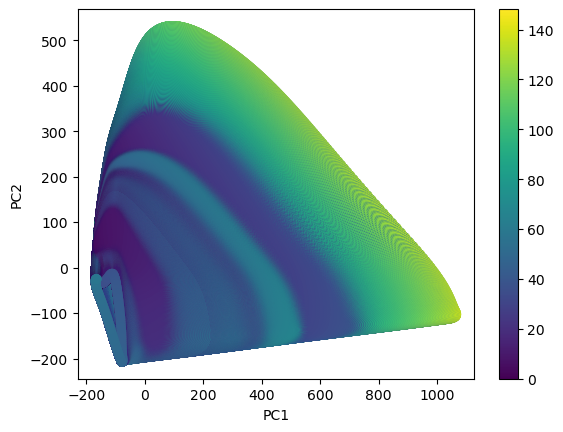

In [55]:
# Scatterplot of ERL PCA results, color corresponds to time
ERL_lower_ODE = int(len(data_DMSO))
ERL_upper_ODE = int(len(principal) - 1)

fig = plt.scatter(principal.iloc[ERL_lower_ODE:ERL_upper_ODE, 0], principal.iloc[ERL_lower_ODE:ERL_upper_ODE, 1], 
                  c=data_ODE['Time'][ERL_lower_ODE:ERL_upper_ODE])
plt.colorbar(fig)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.savefig('PCA_ERLfig.png')
plt.show()

## Stochastic Data

In [148]:
# Put all DMSO and ERL data in separate dataframes

data_DMSO_stoch = pd.DataFrame()
data_ERL_stoch = pd.DataFrame()

for i in range(0,len(filenames_sp)):
    if "dmso" in filenames_sp[i]:
        prot_tmp_stoch = pd.read_csv(filenames_sp[i], sep=",", header=None, usecols = range(0,18))
        
        upper_range = round(len(prot_tmp_stoch)*0.1,2)
        time = np.linspace(0,upper_range-0.1,len(prot_tmp_stoch))
        prot_tmp_stoch.insert(0,'0',time)
        
        if data_DMSO_stoch.empty:
            data_DMSO_stoch = prot_tmp_stoch
        else:
            data_DMSO_stoch = pd.concat([data_DMSO_stoch, prot_tmp_stoch], axis=0)
    else:
        prot_tmp_stoch = pd.read_csv(filenames_sp[i], sep=",", header=None, usecols = range(0,18))
        
        upper_range = round(len(prot_tmp_stoch)*0.1,2)
        time = np.linspace(0,upper_range-0.1,len(prot_tmp_stoch))
        prot_tmp_stoch.insert(0,'0',time)
    
        if data_ERL_stoch.empty:
            data_ERL_stoch = prot_tmp_stoch
        else:
            data_ERL_stoch = pd.concat([data_ERL_stoch, prot_tmp_stoch], axis=0)

In [149]:
# All data together
data_stoch = pd.concat([data_DMSO_stoch, data_ERL_stoch], axis=0)
data_stoch.columns = ["Time", "skp2", "p21", "pp21", "cdh1a", "myc", "cycD", "cycD-p21", 
    "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
    "cycB", "cycB-p21", "cdc20"]
data_stoch

,Time,skp2,p21,pp21,cdh1a,myc,cycD,cycD-p21,Rb,pRb,E2F,E2F-Rb,cycE,cycE-p21,cycA,cycA-p21,cycB,cycB-p21,cdc20
0,0.0,12.0,1.0,16.0,6.0,194.0,139.0,47.0,1.0,5.0,242.0,124.0,19.0,163.0,3.0,102.0,2.0,17.0,2.0
1,0.1,12.0,2.0,20.0,5.0,195.0,137.0,43.0,1.0,3.0,244.0,123.0,18.0,157.0,4.0,102.0,2.0,17.0,2.0
2,0.2,12.0,0.0,20.0,5.0,195.0,136.0,40.0,1.0,3.0,244.0,121.0,19.0,160.0,4.0,103.0,2.0,19.0,2.0
3,0.3,12.0,0.0,13.0,4.0,196.0,137.0,40.0,1.0,5.0,239.0,122.0,20.0,160.0,4.0,104.0,2.0,20.0,2.0
4,0.4,12.0,0.0,12.0,3.0,197.0,137.0,41.0,1.0,6.0,235.0,116.0,23.0,158.0,4.0,108.0,2.0,20.0,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
199996,19999.6,6.0,14.0,0.0,188.0,12.0,102.0,42.0,4.0,151.0,41.0,3.0,83.0,2.0,2.0,0.0,0.0,7.0,0.0
199997,19999.7,6.0,12.0,2.0,187.0,13.0,105.0,42.0,5.0,155.0,37.0,2.0,84.0,3.0,1.0,0.0,0.0,7.0,0.0
199998,19999.8,6.0,11.0,2.0,191.0,9.0,109.0,39.0,5.0,135.0,57.0,2.0,84.0,3.0,1.0,0.0,0.0,7.0,0.0
199999,19999.9,5.0,11.0,2.0,192.0,8.0,110.0,39.0,5.0,131.0,60.0,2.0,84.0,3.0,1.0,0.0,0.0,7.0,0.0


In [150]:
# use the pca on all the data (without the time column)
principalComponents_stoch = pca.transform(data_stoch.iloc[:,1:])

# add results to a dataframe
principal_stoch = pd.DataFrame(data = principalComponents_stoch, columns = ['principal component 1', 'principal component 2'])
principal_stoch

,principal component 1,principal component 2
0,-103.606440,-86.207424
1,-100.199102,-86.043029
2,-100.028836,-88.329149
3,-106.787726,-89.755741
4,-107.365318,-90.841417
...,...,...
1200001,-93.901455,-63.794840
1200002,-91.475090,-66.054857
1200003,-93.374110,-61.246471
1200004,-93.789578,-59.763875


### Scatter plot of all stochastic data

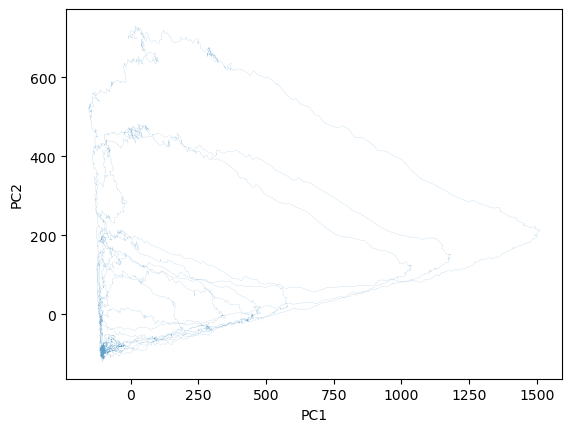

In [151]:
# Scatterplot of all PCA results

fig = plt.plot(principal_stoch.iloc[:5000, 0], principal_stoch.iloc[:5000, 1], lw=0.1, alpha=0.7)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()

### Plot of all stochastic DMSO data

In [138]:
# use the pca on all the data (without the time column)
principalComponents_stoch = pca.transform(prot_tmp_stoch.iloc[:,1:])

# add results to a dataframe
principal_stoch = pd.DataFrame(data = principalComponents_stoch, columns = ['principal component 1', 'principal component 2'])
principal_stoch

C:\Users\olesk\anaconda3\envs\ECM_model\lib\site-packages\sklearn\base.py:465: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


,principal component 1,principal component 2
0,-103.606440,-86.207424
1,-108.140408,-87.270891
2,-115.920391,-88.375412
3,-114.953133,-90.619733
4,-115.141222,-88.563452
...,...,...
199996,-93.901455,-63.794840
199997,-91.475090,-66.054857
199998,-93.374110,-61.246471
199999,-93.789578,-59.763875


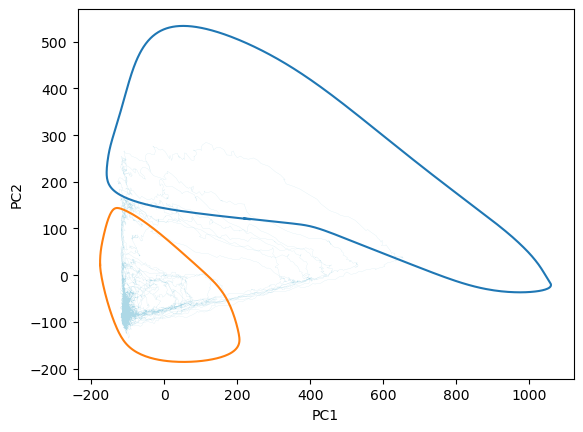

In [34]:
fig = plt.plot(principal_stoch.iloc[:10000, 0], principal_stoch.iloc[:10000, 1], c='lightblue', lw=0.1)
plt.plot(principal.iloc[erl_lo, 0], principal.iloc[erl_lo, 1])
plt.plot(principal.iloc[erl_int, 0], principal.iloc[erl_int, 1])

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()

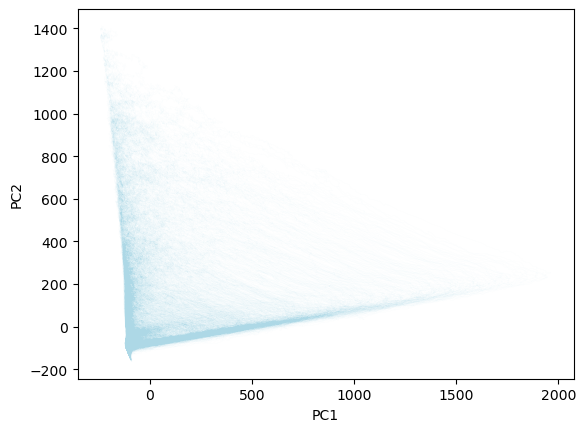

In [35]:
# Plot of DMSO PCA results

DMSO_upper_stoch = int(len(data_DMSO_stoch) - 1)

fig = plt.plot(principal_stoch.iloc[0:DMSO_upper_stoch, 0], principal_stoch.iloc[0:DMSO_upper_stoch, 1], c='lightblue', lw=0.01)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()

#### Overlay on ODE data

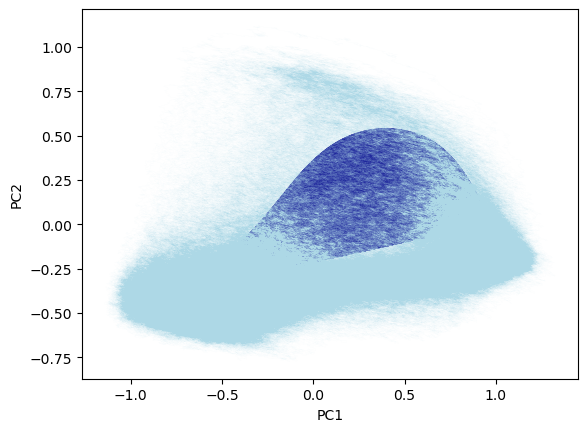

In [27]:
fig = plt.plot(principal.iloc[0:DMSO_upper_ODE, 0], principal.iloc[0:DMSO_upper_ODE, 1], c='darkblue', lw=1)
plt.plot(principal_stoch.iloc[0:DMSO_upper_stoch, 0], principal_stoch.iloc[0:DMSO_upper_stoch, 1], c='lightblue', lw=0.01)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()

### Plot of all stochastic ERL data

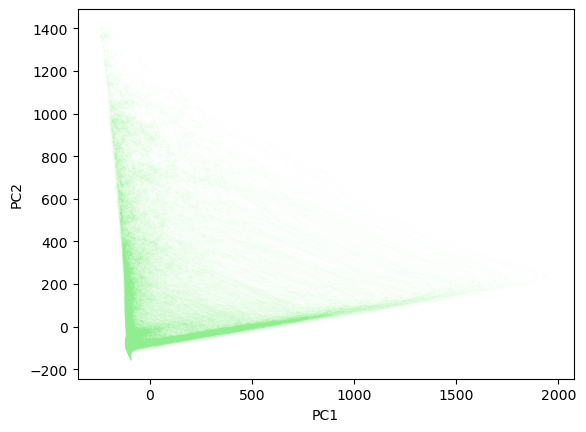

In [36]:
# Plot of ERL PCA results
ERL_lower_stoch = int(len(data_DMSO_stoch))
ERL_upper_stoch = int(len(principal_stoch) - 1)

fig = plt.plot(principal_stoch.iloc[ERL_lower_stoch:ERL_upper_stoch, 0], principal_stoch.iloc[ERL_lower_stoch:ERL_upper_stoch, 1], c='lightgreen', lw=0.01)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()

#### Overlay on ODE data

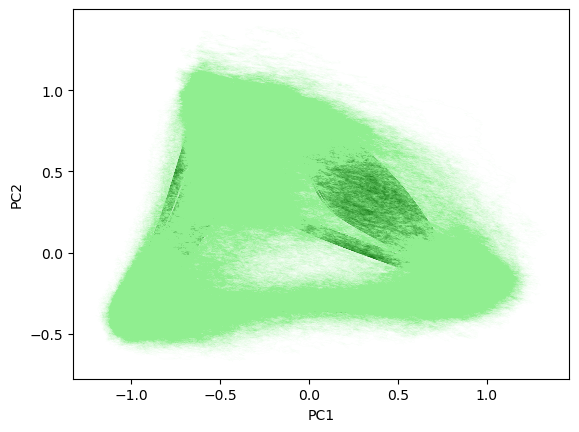

In [24]:
fig = plt.plot(principal.iloc[ERL_lower_ODE:ERL_upper_ODE, 0], principal.iloc[ERL_lower_ODE:ERL_upper_ODE, 1], c='darkgreen', lw=1)
plt.plot(principal_stoch.iloc[ERL_lower_stoch:ERL_upper_stoch, 0], principal_stoch.iloc[ERL_lower_stoch:ERL_upper_stoch, 1], c='lightgreen', lw=0.01)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()

### Scatter plot of all stochastic data overalyed on ODE data

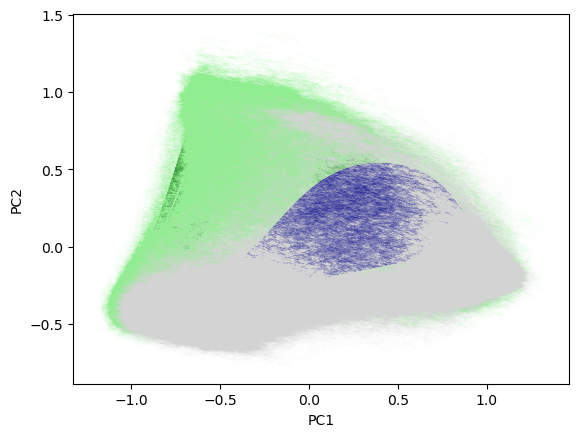

In [25]:
# All plots
fig = plt.plot(principal.iloc[ERL_lower_ODE:ERL_upper_ODE, 0], principal.iloc[ERL_lower_ODE:ERL_upper_ODE, 1], c='darkgreen', lw=1)
plt.plot(principal_stoch.iloc[ERL_lower_stoch:ERL_upper_stoch, 0], principal_stoch.iloc[ERL_lower_stoch:ERL_upper_stoch, 1], c='lightgreen', lw=0.01)
plt.plot(principal.iloc[0:DMSO_upper_ODE, 0], principal.iloc[0:DMSO_upper_ODE, 1], c='darkblue', lw=1)
plt.plot(principal_stoch.iloc[0:DMSO_upper_stoch, 0], principal_stoch.iloc[0:DMSO_upper_stoch, 1], c='lightgrey', lw=0.01)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()